Code: https://github.com/zhurleonid/corporate-risk-management
(`homework_2/hw2_code.ipynb`)

The write-up is below. The code is appended at the end.

# A note on the problem sheet

The put price is printed there as
$P^{BS}(t,x) = x\big(N(d_1) - 2\big) + Ke^{-r(T-t)}\big(1 - N(d_2)\big)$.
The coefficient should be $N(d_1) - 1$, since put-call parity gives

$$P^{BS} = Ke^{-r\tau}N(-d_2) - xN(-d_1) = x\big(N(d_1) - 1\big) + Ke^{-r\tau}\big(1 - N(d_2)\big),$$

and that is also what makes the quoted $\delta = N(d_1) - 1$ correct. I use
$N(d_1) - 1$ throughout.

# Problem 1: loss operators

Take the risk factor to be $z_t = \ln S_t$ and write $x = X_{t+\Delta}$ for the
log return, so that $S_{t+\Delta} = S_t e^{x}$. Under $\mathbb{P}$,

$$X_{t+\Delta} \sim N\!\left(\left(\mu - \tfrac12\sigma^2\right)\Delta,\ \sigma^2\Delta\right). \tag{1}$$

The portfolio value is a function of $t$ and $z$,

$$V_t = f(t, z_t), \qquad f(t,z) = M\left(\lambda e^{z} - P^{BS}\!\left(t, e^{z}\right)\right), \tag{2}$$

where $\lambda = \delta(t, S_t)$ is a constant, fixed at its time $t$ value for the whole period.

## Full loss operator

Since $L_{t+\Delta} = -(V_{t+\Delta} - V_t)$,

$$L_{t+\Delta} = -M\left(\lambda S_{t+\Delta} - P^{BS}(t+\Delta, S_{t+\Delta})\right) + M\left(\lambda S_t - P^{BS}(t, S_t)\right),$$

and substituting $S_{t+\Delta} = S_t e^{x}$,

$$\ell_{[t]}(x) = M\left[\lambda S_t\left(1 - e^{x}\right) + P^{BS}\!\left(t+\Delta, S_t e^{x}\right) - P^{BS}(t, S_t)\right]. \tag{3}$$

The first term is the profit on the share position, which is held fixed, and
the second is the change in value of the short options. The put price enters
with a plus sign because we are short.

## (a) Linearized loss operator

The time derivative of (2) is $f_t(t, z_t) = -M\theta(t, S_t)$. For the
derivative in $z$, the chain rule gives

$$f_z(t,z) = M\left(\lambda e^{z} - \partial_x P^{BS}\!\left(t, e^{z}\right)e^{z}\right) = Me^{z}\left(\lambda - \delta\!\left(t, e^{z}\right)\right). \tag{4}$$

At $z = z_t$ we have $e^{z_t} = S_t$, and $\lambda = \delta(t, S_t)$ by construction, so

$$f_z(t, z_t) = MS_t\left(\lambda - \delta(t, S_t)\right) = 0. \tag{5}$$

The linearized operator is therefore

$$\ell^{\Delta}_{[t]}(x) = -\left[f_t(t, z_t)\Delta + f_z(t, z_t)x\right] = M\,\theta(t, S_t)\,\Delta. \tag{6}$$

It does not depend on $x$ at all. Its distribution is a point mass at
$M\theta\Delta$, with zero variance.

This is exactly what the delta hedge is for. To first order the portfolio has
no exposure to the risk factor, so the only thing the linear approximation can
see is the time decay over the period. Since $\theta < 0$ for the put,
$\ell^{\Delta}_{[t]} < 0$, and the approximation says the position collects
$|M\theta\Delta|$ with certainty.

## (b) Second order loss operator

Differentiating (4) once more in $z$, and using $\partial_z \delta(t, e^{z}) = \gamma(t, e^{z})e^{z}$,

$$f_{zz}(t,z) = Me^{z}\left(\lambda - \delta\!\left(t, e^{z}\right)\right) - Me^{2z}\gamma\!\left(t, e^{z}\right).$$

The first term vanishes at $z_t$ by (5), so $f_{zz}(t, z_t) = -MS_t^2\gamma(t, S_t)$
and, dropping the $f_{tt}$ and $f_{tz}$ terms as instructed,

$$\ell^{\Delta,2}_{[t]}(x) = M\,\theta(t, S_t)\,\Delta + \tfrac12 MS_t^2\,\gamma(t, S_t)\,x^2. \tag{7}$$

Short options means short gamma, so the position loses in proportion to $x^2$
whichever way the stock moves, and the theta term is what pays for that.
Setting (7) to zero gives a break even move of

$$|x^*| = \sqrt{\frac{-2\theta\Delta}{S_t^2\gamma}} = 0.0975,$$

which is close to the ten day standard deviation $\sigma\sqrt\Delta = 0.0977$.
That is what the Black-Scholes PDE
$\theta + rS\delta + \tfrac12\sigma^2S^2\gamma = rP^{BS}$ forces when $r$ is small.

# Problem 2: simulation

## Method

All three operators are evaluated on the same draws of $X$, so the losses can
be compared path by path.

## Pseudocode

```
inputs: mu, sigma, r, T, Delta, S0, K, M, N

tau0 = T,  tau1 = T - Delta
P0     = P_BS(tau0, S0)
lambda = delta(tau0, S0)
gamma0 = gamma(tau0, S0)
theta0 = theta(tau0, S0)
c_theta = M * theta0 * Delta
c_gamma = 0.5 * M * S0^2 * gamma0

draw X_1 ... X_N iid from
    N((mu - sigma^2/2)*Delta, sigma^2*Delta)

for i = 1 ... N:
    S1        = S0*exp(X_i)
    L_full[i] = M * (lambda*(S0 - S1) + P_BS(tau1, S1) - P0)
    L_lin[i]  = c_theta
    L_quad[i] = c_theta + c_gamma * X_i^2

for each of the three samples:
    report mean, standard deviation
    VaR_alpha = empirical alpha quantile
    ES_alpha  = mean of the sample at or above VaR_alpha
    plot a normalized histogram
```

With $t = 0$ the time to maturity is $\tau_0 = 0.291667$ and
$\tau_1 = 0.251984$. The time 0 quantities are

$$P^{BS}(0, S_0) = 27.10,\qquad \lambda = -0.6087,\qquad \gamma = 0.009502,$$
$$\theta = -26.47,\qquad V_0 = -11{,}992.79,$$

so $M\theta\Delta = -105.02$ and $\tfrac12 MS_0^2\gamma = 11{,}050.79$. Note that
$S_0 < K$, so $\lambda < 0$ and the share position is in fact a short position
of about 61 shares, which is the right hedge for a short in-the-money put.

## Results

$$\begin{array}{l r r r r r r}
\hline
\text{Operator} & \text{mean} & \text{s.d.} & \text{VaR}_{0.95} & \text{ES}_{0.95} & \text{VaR}_{0.99} & \text{ES}_{0.99} \\
\hline
\text{Full} & 0.78 & 155.52 & 304.52 & 500.44 & 611.89 & 846.67 \\
\text{Linearized} & -105.02 & 0.00 & -105.02 & -105.02 & -105.02 & -105.02 \\
\text{Second order} & 0.28 & 149.68 & 300.05 & 486.30 & 598.36 & 797.57 \\
\hline
\end{array}$$

*Simulated loss distributions, $N = 100{,}000$ trials, in dollars.*

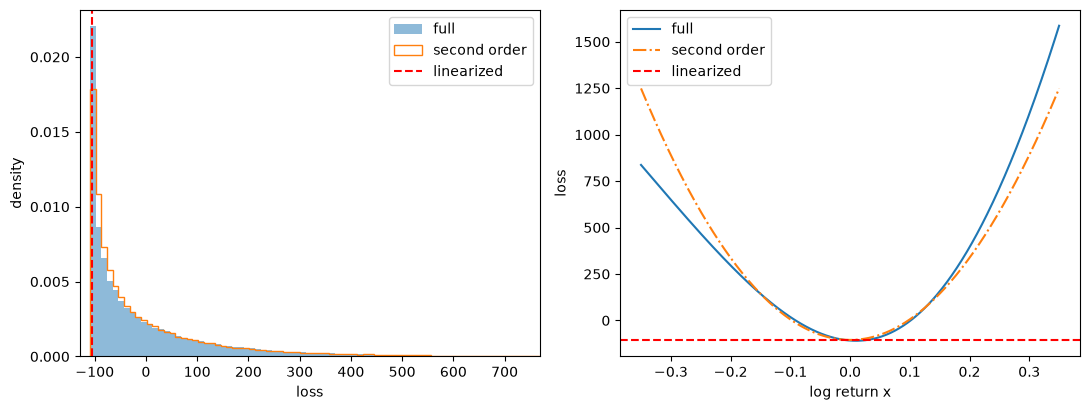

*Left: histogram estimates of the loss densities. The top 0.5% is cut off so the bulk is visible. Right: the three operators as functions of the log return.*

The loss distribution is skewed to the right and bounded below. The best
outcome is a small move, which collects the time decay, and 67.7% of the trials
end in a gain, but the losses have no upper bound and $\text{ES}_{0.99}$ is 847.
That is the usual shape for a short gamma position.

The mean is small, 0.78 against a standard deviation of 156. Taking
expectations in (7) and using the Black-Scholes PDE to replace $\theta$,

$$\mathbb{E}\left[\ell^{\Delta,2}_{[t]}\right] = M\theta\Delta + \tfrac12 MS_0^2\gamma\left(m^2 + \sigma^2\Delta\right) = -r\Delta V_0 + \tfrac12 MS_0^2\gamma\, m^2 = 0.61,$$

with $m = (\mu - \tfrac12\sigma^2)\Delta$. The theta collected is almost exactly
cancelled by the expected gamma loss, and what is left is the financing on the
portfolio value.

## How well do the approximations work

The linearized operator is useless here. It has zero variance and gives
$\text{VaR}_\alpha = -105.02$ at every confidence level, so it claims the
position cannot lose money, while the true $\text{VaR}_{0.99}$ is 612. Its root
mean squared error against the full operator is 188, which is larger than the
standard deviation of the loss it is meant to approximate. The reason is that
linearization keeps only the $f_z$ term, and $f_z = 0$ is precisely what the
delta hedge arranges, so the approximation discards everything that carries
the remaining risk.

The second order operator works well. Its root mean squared error is 28, the
standard deviation is within 3.8% of the true one, and $\text{VaR}_{0.95}$ is
within 1.5%. In the left panel of the figure the two histograms are almost on
top of each other.

The errors do grow further into the tail. The relative error is 1.5% at
$\text{VaR}_{0.95}$, 2.2% at $\text{VaR}_{0.99}$ and 5.8% at $\text{ES}_{0.99}$,
and the sign is the same in every case, with the approximation understating the
loss. The right panel of the figure shows why. The true loss curve is steeper
than the parabola for large positive returns, because the parabola ignores the
third order term. For a short gamma book this is the wrong direction to be
wrong in, so I would use the full operator for tail measures even though the
second order one is fine for $\text{VaR}_{0.95}$.

One last observation. The second order error does not vanish as $x \to 0$. At
$x = 0$ the full operator gives $-108.25$ while the second order one gives
$-105.02$. The gap is the $\tfrac12 f_{tt}\Delta^2$ term that we were told to
drop, so the approximation is accurate in $x$ near the money but still only
linear in time.

# Appendix: source code

The code below produces every figure and number above.

In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

mu = 0.16905
sigma = 0.4907
r = 0.0011888
T = 0.291667
dt = 10 / 252
S0 = 152.51
K = 170.0
M = 100
N = 100000

In [2]:
def d1(tau, S):
    return ((np.log(S / K) + (r + sigma**2 / 2) * tau)
            / (sigma * np.sqrt(tau)))

def d2(tau, S):
    return d1(tau, S) - sigma * np.sqrt(tau)

def put(tau, S):
    # note N(d1)-1, not N(d1)-2 as printed on the sheet
    return (S * (norm.cdf(d1(tau, S)) - 1)
            + K * np.exp(-r * tau) * (1 - norm.cdf(d2(tau, S))))

def delta(tau, S):
    return norm.cdf(d1(tau, S)) - 1

def gamma(tau, S):
    return norm.pdf(d1(tau, S)) / (S * sigma * np.sqrt(tau))

def theta(tau, S):
    return (-sigma * S * norm.pdf(d1(tau, S)) / (2 * np.sqrt(tau))
            + K * r * np.exp(-r * tau) * (1 - norm.cdf(d2(tau, S))))

In [3]:
# time 0 quantities
tau0 = T
tau1 = T - dt
P0 = put(tau0, S0)
lam = delta(tau0, S0)
g0 = gamma(tau0, S0)
th0 = theta(tau0, S0)
V0 = M * (lam * S0 - P0)

print("put price     ", round(P0, 4))
print("lambda        ", round(lam, 6))
print("gamma         ", round(g0, 8))
print("theta         ", round(th0, 4))
print("V0            ", round(V0, 2))
print("M*theta*dt    ", round(M * th0 * dt, 4))
print("0.5*M*S0^2*gam", round(0.5 * M * S0**2 * g0, 2))

put price      27.099
lambda         -0.608674
gamma          0.00950226
theta          -26.4662
V0             -11992.79
M*theta*dt     -105.0248
0.5*M*S0^2*gam 11050.79


In [4]:
def loss_full(x):
    return M * (lam * S0 * (1 - np.exp(x))
                + put(tau1, S0 * np.exp(x)) - P0)

def loss_lin(x):
    return M * th0 * dt * np.ones_like(x)

def loss_quad(x):
    return M * th0 * dt + 0.5 * M * S0**2 * g0 * x**2

In [5]:
# break-even move of the second order operator, against the ten-day sd
x_star = np.sqrt(-2 * th0 * dt / (S0**2 * g0))
print("break-even |x*|", round(x_star, 4))
print("sigma*sqrt(dt) ", round(sigma * np.sqrt(dt), 4))

break-even |x*| 0.0975
sigma*sqrt(dt)  0.0977


In [6]:
np.random.seed(1)
x = np.random.normal((mu - sigma**2 / 2) * dt, sigma * np.sqrt(dt), N)
Lfull = loss_full(x)
Llin = loss_lin(x)
Lquad = loss_quad(x)

def var_es(L, a):
    v = np.quantile(L, a)
    return v, L[L >= v].mean()

print("op         mean      sd    VaR95    ES95   VaR99    ES99")
for name, L in [("full", Lfull), ("linear", Llin), ("quad", Lquad)]:
    v95, e95 = var_es(L, 0.95)
    v99, e99 = var_es(L, 0.99)
    print("%-8s %7.2f %7.2f %7.2f %7.2f %7.2f %7.2f"
          % (name, L.mean(), L.std(ddof=1), v95, e95, v99, e99))

op         mean      sd    VaR95    ES95   VaR99    ES99
full        0.78  155.52  304.52  500.44  611.89  846.67
linear   -105.02    0.00 -105.02 -105.02 -105.02 -105.02
quad        0.28  149.68  300.05  486.30  598.36  797.57


In [7]:
for name, L in [("linear", Llin), ("quad", Lquad)]:
    err = L - Lfull
    print("%-8s rmse %7.2f" % (name, np.sqrt((err**2).mean())))
print("fraction of gains", round((Lfull < 0).mean(), 4))
print("loss_full(0)", round(loss_full(np.array([0.0]))[0], 2))

# analytic mean of the second order operator:
#     -r*dt*V0 + 0.5*M*S0^2*gamma*m^2
m = (mu - sigma**2 / 2) * dt
EL_quad = -r * dt * V0 + 0.5 * M * S0**2 * g0 * m**2
print("E[quad] analytic", round(EL_quad, 2))

linear   rmse  188.09
quad     rmse   27.98
fraction of gains 0.6765
loss_full(0) -108.25
E[quad] analytic 0.61


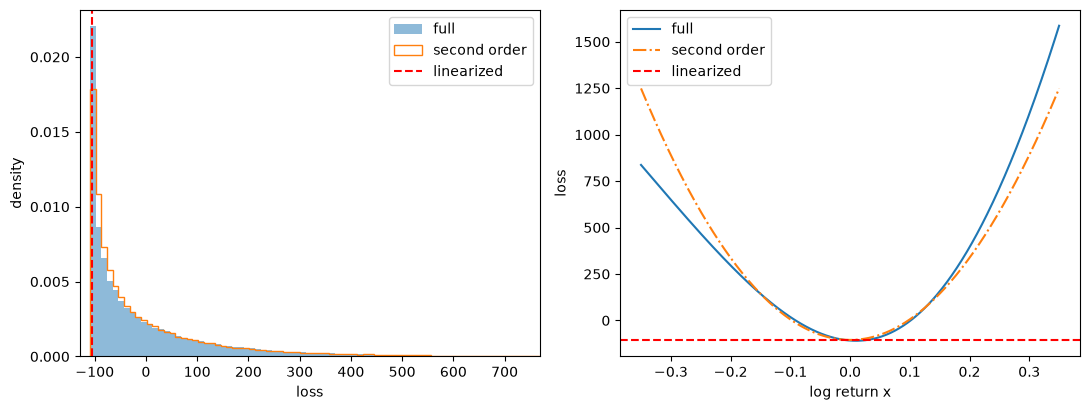

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

top = np.quantile(Lfull, 0.995)
bins = np.linspace(Lfull.min(), top, 80)
ax[0].hist(Lfull, bins=bins, density=True, alpha=0.5, label="full")
ax[0].hist(Lquad, bins=bins, density=True, histtype="step",
           label="second order")
ax[0].axvline(Llin[0], color="r", ls="--", label="linearized")
ax[0].set_xlim(Lfull.min() - 20, top)
ax[0].set_xlabel("loss")
ax[0].set_ylabel("density")
ax[0].legend()

xg = np.linspace(-0.35, 0.35, 500)
ax[1].plot(xg, loss_full(xg), label="full")
ax[1].plot(xg, loss_quad(xg), ls="-.", label="second order")
ax[1].axhline(Llin[0], color="r", ls="--", label="linearized")
ax[1].set_xlabel("log return x")
ax[1].set_ylabel("loss")
ax[1].legend()

fig.tight_layout()
plt.show()